---
## Normalisation of raw data
> Demonstrates how a difference in scale and range can make a feature dominate over other features
- instead of measuring the length of a song in seconds, we measure in minutes


In [ ]:
from ml_lib import *
features_in_mins, labels = read_labelled_data('labelled_in_mins.csv')
plot_labelled_data(features_in_mins, labels, x_units="minutes", y_label="song tempo", x_label="song length")

**<u>Observe:</u>**
- Note that the distance measure we used between two points is 
    - $(\Delta \text{tempo})^2 + (\Delta \text{length})^2$, the squared Euclidean distance. 
- `tempo`: units is bpm (100 - 140)
- `length`: units is minutes (4.17 - 5.25)
- the scale mismatch introduces an implicit, unintended dominance of the `tempo` feature over the `length` feature, making the `length` feature irrelevant.
- KNN is "blind to units", it operates only on the numerical values.


In [ ]:
### Demonstrating the effects of feature with a dominant scale
import pandas as pd
from ml_lib import *

cols = ["length", "tempo", "genre"]
df_sec = pd.read_csv("labelled.csv", header=None, names=cols)
df_min = pd.read_csv("labelled_in_mins.csv", header=None, names=cols)

genre_colors = {"Rock": "#e74c3c", "Jazz": "#3498db", "Classical": "#2ecc71"}
genre_shapes = {"Rock":'o', "Jazz":'s', "Classical":'^'}
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

for ax, df, unit, title in [
    (axes[0], df_sec, "seconds", "Length in SECONDS  (range \u2248 250\u2013315)"),
    (axes[1], df_min, "minutes", "Length in MINUTES  (range \u2248 4.17\u20135.25)"),
]:
    for genre, color in genre_colors.items():
        sub = df[df["genre"] == genre]
        ax.scatter(sub["length"], sub["tempo"], color=color, label=genre, s=80,
                   marker=genre_shapes[genre],
                   edgecolor="black", linewidth=0.6, zorder=3)

    ax.set_xlabel(f"Length ({unit})")
    ax.set_ylabel("Tempo (bpm)")
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")   # <-- key: 1 length-unit == 1 bpm-unit on screen
    ax.grid(alpha=0.3, zorder=0)
    lo, hi = df["tempo"].min() - 20, df["tempo"].max() + 20
    ax.set_ylim(lo, hi)

axes[0].legend(loc="upper left", frameon=True)

fig.suptitle(
    "Same data, two units for 'length' \u2192 KNN's Euclidean distance is NOT unit-aware\n"
    "(axes drawn with equal scale: 1 bpm-unit = 1 length-unit, exactly as KNN's raw distance sees it)",
    fontsize=11
)
fig.tight_layout(rect=[0, 0, 1, 0.90])
# fig.savefig("knn_scale_effect.png", dpi=150)
plt.show()

In [ ]:
### Using Un-normalised data to predict 

# Prompt for length (in mins) and tempo of new song.
# Enter k: 4, length = 4.45 (267s), tempo=120
# 

k = int(input('Enter k: '))
length_new = float(input('Enter length of song (minutes): '))
tempo_new = float(input('Enter tempo of song (bpm): '))

# Output predicted genre.

print(f'Prediction: {predict(k, features_in_mins, labels, (length_new, tempo_new))}')
print(f'Probabilities {predict_probabilities(k, features_in_mins, labels, (length_new, tempo_new))}')

<div class="alert">

Observe from the left plot that the test data is near the "Rock" cluster BUT due to differences in scale between tempo(bpm) and length(minutes), the tempo feature completely dominate the square distance calculation.

</div>

In [ ]:
def normalise_data(features):
    """Applies min-max normalisation to each feature column.
    
    Takes a list of feature vectors (list of lists of floats) and rescales
    each column independently to the range [0, 1], so that features measured
    in different units contribute equally to distance calculations.
    """
    num_features = len(features[0])
    normalised = [row[:] for row in features]  # copy so original data isn't mutated

    for col in range(num_features):
        column_values = [row[col] for row in features]
        col_min = min(column_values)
        col_max = max(column_values)

        for row in normalised:
            row[col] = (row[col] - col_min) / (col_max - col_min)

    return normalised

def normalise_new_point(new_features, original_features):
    """Normalises a single new data point using the min/max of the training data.
    
    new_features: list of raw feature values for the new point, e.g. [new_length, new_tempo]
    original_features: the ORIGINAL (unnormalised) training features, used to derive min/max
    """
    num_features = len(original_features[0])
    normalised_point = []

    for col in range(num_features):
        column_values = [row[col] for row in original_features]
        col_min = min(column_values)
        col_max = max(column_values)

        normalised_value = (new_features[col] - col_min) / (col_max - col_min)
        normalised_point.append(normalised_value)

    return normalised_point

In [15]:
## numpy code
# np.ptp(a,axis) == np.max(a, axis) - np.min(a,axis)

import numpy as np

def np_normalise_data(features:np.ndarray)->np.ndarray:
    return (features - np.min(features,axis=0))/ np.ptp(features,axis=0)

def np_normalise_new_points(features:np.ndarray, new_points:np.ndarray)-> np.ndarray:
    return (new_points - np.min(features,axis=0)) / np.ptp(features,axis=0)


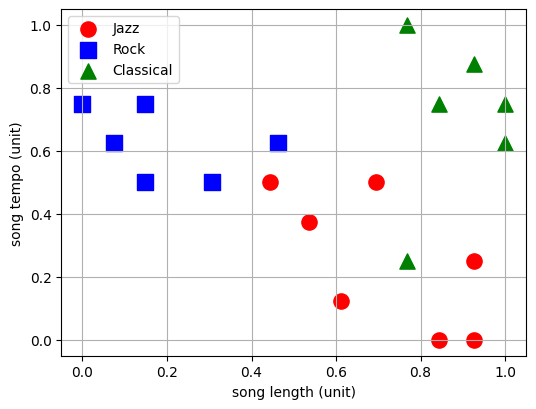

In [9]:
norm_features = normalise_data(features_in_mins)
plot_labelled_data(norm_features, labels, x_units="unit", y_units="unit")

In [ ]:
# numpy code

norm_features = np_normalise_data(np.array(features_in_mins))
plot_labelled_data(norm_features, labels, x_units="unit", y_units="unit")

In [ ]:
### Using Normalised features 
# Prompt for length and tempo of new song.
# Enter k: 4, length = 4.45, tempo=120
k = int(input('Enter k: '))
length_new = float(input('Enter length of song (minutes): '))
tempo_new = float(input('Enter tempo of song (bpm): '))
normalised_new_point = normalise_new_point((length_new, tempo_new), features_in_mins)
# Output predicted genre.
print(normalised_new_point)
print(f'Prediction: {predict(k, norm_features, labels, normalised_new_point)}')
print(f'Probabilities {predict_probabilities(k, norm_features, labels, normalised_new_point)}')

---
## Scaling Techniques

There are two scaling techniques:
- Feature Scaling
    - MinMax Scaling , range of values normalise to [0,1]
    - Standardisation Scaling (z-score normalisation) mean at 0 , std = 1 
- L2 Normalisation
    - Normalise each row (features) into a unit vector, rnage of values [-1,1]

